# 🚀 ChurnShield AI — Modelos Avançados + Ensemble

**Objetivo:** Treinar modelos de gradient boosting e criar o ensemble final.

**Modelos:**
- XGBoost
- LightGBM
- CatBoost
- Voting Ensemble (combinação dos 3)

In [1]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yaml

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import roc_auc_score, f1_score, RocCurveDisplay
from sklearn.model_selection import StratifiedKFold, cross_val_score

from src.data.data_loader import ChurnDataLoader
from src.features.feature_engineering import build_feature_pipeline, apply_smote

with open('../config/config.yaml') as f:
    CONFIG = yaml.safe_load(f)

print('✅ Pronto!')

✅ Pronto!


In [2]:
# Preparar dados
loader = ChurnDataLoader(CONFIG)
df = loader.load(use_synthetic=True)
X_train, X_test, y_train, y_test = loader.get_splits(df)

pipeline = build_feature_pipeline(CONFIG)
X_train_fe = pipeline.fit_transform(X_train, y_train)
X_test_fe = pipeline.transform(X_test)
X_train_res, y_train_res = apply_smote(X_train_fe, y_train)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print('✅ Dados prontos!')

2026-04-26 01:02:01.745 | INFO     | src.data.data_loader:load:267 - Arquivo não encontrado. Usando dataset sintético...
2026-04-26 01:02:01.747 | INFO     | src.data.data_loader:generate_synthetic_dataset:50 - Gerando dataset sintético com 7,043 amostras...
2026-04-26 01:02:01.775 | SUCCESS  | src.data.data_loader:generate_synthetic_dataset:158 - Dataset gerado: 7,043 linhas | 21 colunas | Churn rate: 22.1%
2026-04-26 01:02:01.814 | INFO     | src.data.data_loader:load:271 - Dataset salvo em: data\raw\churn_data.csv
2026-04-26 01:02:01.823 | INFO     | src.data.data_loader:load:280 - Data hash: becc0750
2026-04-26 01:02:01.828 | SUCCESS  | src.data.data_loader:validate:226 - ✅ Validação de dados: PASSOU em todas as verificações
2026-04-26 01:02:01.836 | INFO     | src.data.data_loader:get_splits:330 - Split: train=5,634 | test=1,409 | churn_train=22.0% | churn_test=22.1%
2026-04-26 01:02:01.837 | INFO     | src.features.feature_engineering:build_feature_pipeline:271 - Pipeline de feat

✅ Dados prontos!


## Treinando Modelos Avançados

In [3]:
models = {
    'XGBoost': XGBClassifier(
        n_estimators=500, max_depth=6, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8,
        random_state=42, verbosity=0
    ),
    'LightGBM': LGBMClassifier(
        n_estimators=500, num_leaves=63, learning_rate=0.05,
        feature_fraction=0.8, bagging_fraction=0.8,
        random_state=42, verbose=-1
    ),
    'CatBoost': CatBoostClassifier(
        iterations=500, depth=6, learning_rate=0.05,
        random_seed=42, verbose=0
    ),
}

results = {}
trained = {}

for name, model in models.items():
    print(f'Treinando {name}...')
    model.fit(X_train_res, y_train_res)
    y_prob = model.predict_proba(X_test_fe)[:, 1]
    y_pred = model.predict(X_test_fe)
    cv_scores = cross_val_score(model, X_train_res, y_train_res, cv=cv, scoring='roc_auc', n_jobs=-1)
    
    results[name] = {
        'roc_auc': roc_auc_score(y_test, y_prob),
        'f1': f1_score(y_test, y_pred),
        'cv_auc': cv_scores.mean(),
        'cv_std': cv_scores.std(),
        'y_prob': y_prob,
    }
    trained[name] = model
    print(f'  ✅ AUC={results[name]["roc_auc"]:.4f} | CV={results[name]["cv_auc"]:.4f}±{results[name]["cv_std"]:.4f}')

Treinando XGBoost...
  ✅ AUC=0.7466 | CV=0.9339±0.0033
Treinando LightGBM...
  ✅ AUC=0.7335 | CV=0.9320±0.0035
Treinando CatBoost...
  ✅ AUC=0.7422 | CV=0.9359±0.0032


In [4]:
# Ensemble
print('Treinando Ensemble...')
ensemble = VotingClassifier(
    estimators=[(n, m) for n, m in trained.items()],
    voting='soft', weights=[1, 1.2, 1]
)
calibrated = CalibratedClassifierCV(ensemble, method='sigmoid', cv=3)
calibrated.fit(X_train_res, y_train_res)

y_prob_ens = calibrated.predict_proba(X_test_fe)[:, 1]
y_pred_ens = calibrated.predict(X_test_fe)

results['Ensemble'] = {
    'roc_auc': roc_auc_score(y_test, y_prob_ens),
    'f1': f1_score(y_test, y_pred_ens),
    'y_prob': y_prob_ens,
}
print(f'  ✅ Ensemble AUC={results["Ensemble"]["roc_auc"]:.4f}')

Treinando Ensemble...
  ✅ Ensemble AUC=0.7310


In [5]:
# Leaderboard final
leaderboard = pd.DataFrame([
    {'Modelo': name, 'AUC-ROC': r['roc_auc'], 'F1-Score': r['f1']}
    for name, r in results.items()
]).sort_values('AUC-ROC', ascending=False)

print('🏆 Leaderboard Final')
leaderboard.style.background_gradient(subset=['AUC-ROC', 'F1-Score'], cmap='RdYlGn')

🏆 Leaderboard Final


,Modelo,AUC-ROC,F1-Score
0,XGBoost,0.746613,0.332657
2,CatBoost,0.742212,0.334711
1,LightGBM,0.733500,0.320000
3,Ensemble,0.731025,0.218182


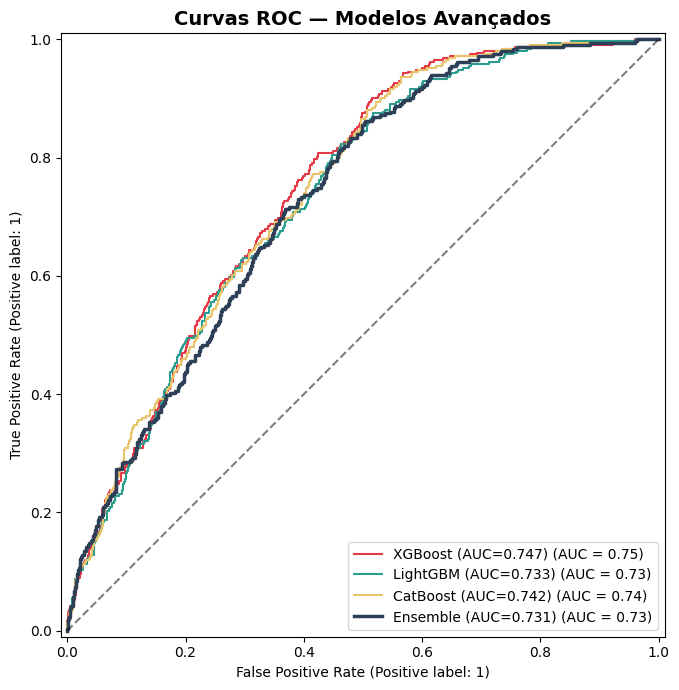

📊 Figura salva em reports/figures/roc_curves.png


In [6]:
# Curvas ROC
fig, ax = plt.subplots(figsize=(10, 7))
colors = ['#E63946', '#2A9D8F', '#E9C46A', '#2E4057']

for (name, r), color in zip(results.items(), colors):
    RocCurveDisplay.from_predictions(
        y_test, r['y_prob'],
        name=f"{name} (AUC={r['roc_auc']:.3f})",
        ax=ax, color=color,
        linewidth=2.5 if name == 'Ensemble' else 1.5
    )

ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)
ax.set_title('Curvas ROC — Modelos Avançados', fontsize=14, fontweight='bold')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('../reports/figures/roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('📊 Figura salva em reports/figures/roc_curves.png')